In [ ]:
!pip install -q mne

# 1) Gerekli araçlar ve senin belirlediğin kayıtlar
from pathlib import Path
import urllib.request
import urllib.parse
import xml.etree.ElementTree as ET
import pandas as pd
import mne

VERI = Path("/content/veri")
VERI.mkdir(parents=True, exist_ok=True)
SUNUCU = "https://s3.amazonaws.com/openneuro.org"

gruplar = {
    "gelistirme": [
        ("035", "04"), ("047", "01"), ("092", "50"),
        ("109", "08"), ("011", "05")
    ],
    "test": [
        ("073", "41"), ("115", "52"), ("089", "61"),
        ("101", "02"), ("079", "15")
    ]
}
assert set(kisi for kisi, _ in gruplar["gelistirme"]).isdisjoint(
    kisi for kisi, _ in gruplar["test"]
), "Aynı kişi geliştirme ve test gruplarında bulunuyor!"


# 2) Yalnız seçilen kaydın dosya listesini ve boyutlarını getir
def dosyalari_listele(prefix):
    bulunanlar = {}
    parametreler = {"list-type": "2", "prefix": prefix}

    while True:
        adres = SUNUCU + "?" + urllib.parse.urlencode(parametreler)
        with urllib.request.urlopen(adres, timeout=60) as yanit:
            kok = ET.fromstring(yanit.read())

        for dosya in kok.findall("{*}Contents"):
            anahtar = dosya.findtext("{*}Key")
            bulunanlar[anahtar] = int(dosya.findtext("{*}Size"))

        if kok.findtext("{*}IsTruncated") != "true":
            return bulunanlar

        parametreler["continuation-token"] = kok.findtext(
            "{*}NextContinuationToken"
        )


# 3) İndirmeden önce 30 dosyanın da listede bulunduğunu kontrol et
plan = []

for grup, secimler in gruplar.items():
    for kisi, run in secimler:
        govde = f"sub-{kisi}_ses-01_task-szMonitoring_run-{run}"
        uzak_klasor = f"ds005873/sub-{kisi}/ses-01"
        listelenen = {}

        for tur in ("eeg", "mov"):
            listelenen.update(dosyalari_listele(
                f"{uzak_klasor}/{tur}/{govde}_"
            ))

        dosyalar = {}
        for tur, klasor, son_ek in [
            ("eeg", "eeg", "eeg.edf"),
            ("mov", "mov", "mov.edf"),
            ("events", "eeg", "events.tsv")
        ]:
            anahtar = f"{uzak_klasor}/{klasor}/{govde}_{son_ek}"
            if anahtar not in listelenen:
                raise FileNotFoundError(f"Dosya listede yok: {anahtar}")

            yol = VERI / anahtar.removeprefix("ds005873/")
            dosyalar[tur] = (anahtar, yol, listelenen[anahtar])

        plan.append({
            "grup": grup, "kisi": kisi, "run": run,
            "dosyalar": dosyalar,
            "secim_gerekcesi": (
                "Kullanıcının önceden belirlediği kayıt; "
                "bilimsel seçim gerekçesi henüz belgelenmedi."
            )
        })

print("İndirilecek dosyalar:")
for kayit in plan:
    for anahtar, yol, boyut in kayit["dosyalar"].values():
        print(f"{anahtar} | {boyut / 1_000_000:.2f} MB")

pd.DataFrame([
    {k: kayit[k] for k in ("grup", "kisi", "run", "secim_gerekcesi")}
    for kayit in plan
]).to_csv(VERI / "secim_kaydi.csv", index=False)


# 4) urllib ile indir; tamamlanmış dosyaları tekrar indirme
for kayit in plan:
    for anahtar, yol, boyut in kayit["dosyalar"].values():
        yol.parent.mkdir(parents=True, exist_ok=True)

        if yol.exists() and yol.stat().st_size == boyut:
            print("Zaten mevcut:", yol.name)
            continue

        print("İndiriliyor:", yol.name, flush=True)
        gecici = yol.with_name(yol.name + ".part")
        urllib.request.urlretrieve(f"{SUNUCU}/{anahtar}", gecici)

        if gecici.stat().st_size != boyut:
            raise IOError(f"İndirme boyutu uyuşmuyor: {yol.name}")

        gecici.replace(yol)


# 5) EDF dosyalarını belleğe oku ve nöbet satırlarını say
kayitlar = {}
ozet_satirlari = []

for kayit in plan:
    kimlik = f"sub-{kayit['kisi']}_run-{kayit['run']}"
    yollar = {
        tur: bilgi[1] for tur, bilgi in kayit["dosyalar"].items()
    }

    eeg = mne.io.read_raw_edf(
        yollar["eeg"], preload=True, verbose="ERROR"
    )
    mov = mne.io.read_raw_edf(
        yollar["mov"], preload=True, verbose="ERROR"
    )
    events = pd.read_csv(yollar["events"], sep="\t")

    if "eventType" not in events.columns:
        raise ValueError(
            f"{kimlik}: eventType sütunu yok. "
            f"Sütunlar: {events.columns.tolist()}"
        )

    nobetler = events[
        events["eventType"].fillna("").astype(str).str.startswith("sz")
    ].copy()

    eeg_hz = float(eeg.info["sfreq"])
    mov_hz = float(mov.info["sfreq"])
    eeg_saat = eeg.n_times / eeg_hz / 3600
    mov_saat = mov.n_times / mov_hz / 3600

    kayitlar[kimlik] = {
        "grup": kayit["grup"],
        "eeg": eeg, "mov": mov,
        "events": events, "nobetler": nobetler
    }

    print(f"\n{kayit['grup'].upper()} | {kimlik}")
    print(f"EEG: {eeg.ch_names} | {eeg_hz:g} Hz | {eeg_saat:.4f} saat")
    print(f"MOV: {mov.ch_names} | {mov_hz:g} Hz | {mov_saat:.4f} saat")
    print("EDF başlangıç zamanları:",
          eeg.info["meas_date"], "/", mov.info["meas_date"])
    print("Olay sütunları:", events.columns.tolist())
    print("eventType dağılımı:",
          events["eventType"].value_counts(dropna=False).to_dict())
    print("'sz' ile başlayan satır sayısı:", len(nobetler))

    if eeg_hz != 256 or mov_hz != 25:
        print("UYARI: Okunan hızlar beklenen EEG=256 / MOV=25 Hz ile farklı.")
    if len(eeg.ch_names) != 2:
        print("UYARI: EEG dosyasında tam 2 kanal bulunmuyor.")

    ozet_satirlari.append({
        "grup": kayit["grup"], "kayit": kimlik,
        "eeg_hz": eeg_hz, "mov_hz": mov_hz,
        "eeg_saat": eeg_saat, "mov_saat": mov_saat,
        "nobet_sayisi": len(nobetler)
    })


# 6) Hesaplanan toplamları beklenen değerlerle karşılaştır
ozet = pd.DataFrame(ozet_satirlari)
ozet.to_csv(VERI / "kayit_ozeti.csv", index=False)

toplamlar = ozet.groupby("grup", sort=False)[
    ["eeg_saat", "mov_saat", "nobet_sayisi"]
].sum()

print("\nHESAPLANAN TOPLAMLAR")
print(toplamlar.to_string())

for grup, beklenen_nobet, beklenen_saat in [
    ("gelistirme", 12, 5.3),
    ("test", 11, 7.0)
]:
    satir = toplamlar.loc[grup]
    durum = "UYUMLU" if satir["nobet_sayisi"] == beklenen_nobet else "FARKLI"
    print(
        f"\n{grup}: nöbet={int(satir['nobet_sayisi'])}, "
        f"beklenen={beklenen_nobet} → {durum}\n"
        f"EEG süresi={satir['eeg_saat']:.4f} saat, "
        f"beklenen≈{beklenen_saat:.1f} saat, "
        f"fark={satir['eeg_saat'] - beklenen_saat:+.4f} saat"
    )

print("\nBu süreler tam kayıt süresidir; yanlış alarm hesabının paydası değildir.")
print("Zaman eşleşmesi, birimler ve motor nöbet etiketleri henüz doğrulanmadı.")
print("Seçim kaydı ve ölçülen özet /content/veri klasörüne kaydedildi.")

İndirilecek dosyalar:
ds005873/sub-035/ses-01/eeg/sub-035_ses-01_task-szMonitoring_run-04_eeg.edf | 5.60 MB
ds005873/sub-035/ses-01/mov/sub-035_ses-01_task-szMonitoring_run-04_mov.edf | 3.52 MB
ds005873/sub-035/ses-01/eeg/sub-035_ses-01_task-szMonitoring_run-04_events.tsv | 0.00 MB
ds005873/sub-047/ses-01/eeg/sub-047_ses-01_task-szMonitoring_run-01_eeg.edf | 7.90 MB
ds005873/sub-047/ses-01/mov/sub-047_ses-01_task-szMonitoring_run-01_mov.edf | 4.96 MB
ds005873/sub-047/ses-01/eeg/sub-047_ses-01_task-szMonitoring_run-01_events.tsv | 0.00 MB
ds005873/sub-092/ses-01/eeg/sub-092_ses-01_task-szMonitoring_run-50_eeg.edf | 2.50 MB
ds005873/sub-092/ses-01/mov/sub-092_ses-01_task-szMonitoring_run-50_mov.edf | 1.57 MB
ds005873/sub-092/ses-01/eeg/sub-092_ses-01_task-szMonitoring_run-50_events.tsv | 0.00 MB
ds005873/sub-109/ses-01/eeg/sub-109_ses-01_task-szMonitoring_run-08_eeg.edf | 2.20 MB
ds005873/sub-109/ses-01/mov/sub-109_ses-01_task-szMonitoring_run-08_mov.edf | 1.09 MB
ds005873/sub-109/ses-01

Bellekteki 073-41 kaydı kullanılıyor.


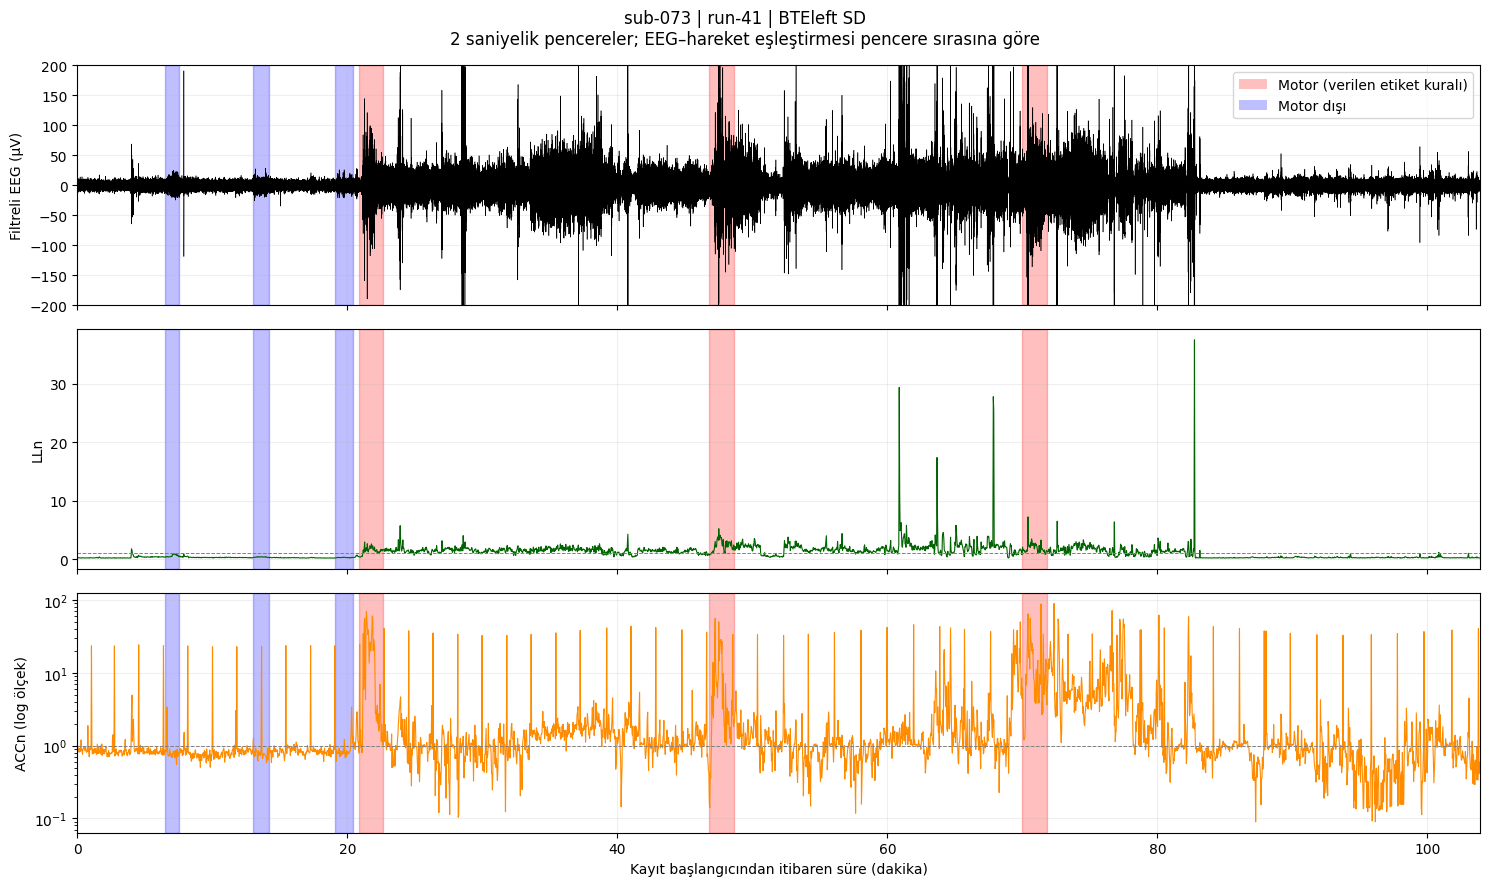

EEG penceresi: 3117; hareket penceresi: 3117; ortak: 3117
Log eksende maskelenen sıfır ACCn penceresi: 0
Şekil kaydedildi: /content/sekil1_ll_acc_sub073.png


In [ ]:
# MNE'yi bu hücrenin çalıştığı Python ortamına kur.
%pip install -q mne

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.signal import butter, filtfilt
from pathlib import Path
import mne

# 1) Önce bellekteki kaydı kullanmayı dene.
kimlik073 = "sub-073_run-41"

if "kayitlar" in globals() and kimlik073 in kayitlar:
    eeg073 = kayitlar[kimlik073]["eeg"]
    mov073 = kayitlar[kimlik073]["mov"]
    events073 = kayitlar[kimlik073]["events"]
    print("Bellekteki 073-41 kaydı kullanılıyor.")

else:
    # Bellekte yoksa önceki hücrenin dosyaları kaydettiği klasöre bak.
    klasor073 = Path("/content/veri/sub-073/ses-01")
    govde073 = "sub-073_ses-01_task-szMonitoring_run-41"

    yollar073 = {
        "eeg": klasor073 / "eeg" / f"{govde073}_eeg.edf",
        "mov": klasor073 / "mov" / f"{govde073}_mov.edf",
        "events": klasor073 / "eeg" / f"{govde073}_events.tsv"
    }

    # Eksik dosya varsa indirme yapmak yerine adını bildirerek dur.
    eksikler073 = [str(yol) for yol in yollar073.values() if not yol.is_file()]
    if eksikler073:
        raise FileNotFoundError(
            "Şu yerel dosyalar bulunamadı; yeniden indirme yapılmadı:\n"
            + "\n".join(eksikler073)
        )

    eeg073 = mne.io.read_raw_edf(
        yollar073["eeg"], preload=True, verbose="ERROR"
    )
    mov073 = mne.io.read_raw_edf(
        yollar073["mov"], preload=True, verbose="ERROR"
    )
    events073 = pd.read_csv(yollar073["events"], sep="\t")
    print("Mevcut yerel dosyalar okundu.")

# 2) Kullanılacak örnekleme hızlarını kontrol et.
if not (
    np.isclose(eeg073.info["sfreq"], 256)
    and np.isclose(mov073.info["sfreq"], 25)
):
    raise ValueError("Beklenen hızlar EEG=256 Hz, hareket=25 Hz.")

# 3) İlk EEG kanalını µV'ye çevir; istenen filtreyi uygula.
# Ham EEG nesnesi değiştirilmez.
kanal073 = eeg073.ch_names[0]
eeg_uv073 = eeg073.get_data(picks=[kanal073])[0] * 1e6
b073, a073 = butter(4, [1, 25], btype="band", fs=256)
eeg_filtreli073 = filtfilt(b073, a073, eeg_uv073)

# 4) EEG'yi 2 saniyelik, örtüşmesiz pencerelere ayır.
# Tam pencereye sığmayan son örnekleri dışarıda bırak.
eeg_pencere073 = 2 * 256
n_eeg073 = len(eeg_filtreli073) // eeg_pencere073
eeg_parcalar073 = eeg_filtreli073[
    :n_eeg073 * eeg_pencere073
].reshape(n_eeg073, eeg_pencere073)

# LL: pencere içindeki ardışık örnek farklarının mutlak değerleri toplamı.
ll073 = np.abs(np.diff(eeg_parcalar073, axis=1)).sum(axis=1)

# 5) EEG cihazının üç ivmeölçer kanalından hareket büyüklüğünü hesapla.
acc_kanallari073 = ["EEG SD ACC X", "EEG SD ACC Y", "EEG SD ACC Z"]
acc_xyz073 = mov073.get_data(picks=acc_kanallari073)
acc_buyukluk073 = np.sqrt(np.sum(acc_xyz073 ** 2, axis=0))

# Hareket büyüklüğünü 2 saniyelik pencerelere ayır ve standart sapmasını al.
acc_pencere073 = 2 * 25
n_acc073 = len(acc_buyukluk073) // acc_pencere073
acc_parcalar073 = acc_buyukluk073[
    :n_acc073 * acc_pencere073
].reshape(n_acc073, acc_pencere073)
acc_std073 = np.std(acc_parcalar073, axis=1, ddof=0)

# 6) Her özelliği kendi kayıt medyanına böl.
if n_eeg073 == 0 or n_acc073 == 0:
    raise ValueError("En az bir tam 2 saniyelik pencere gerekli.")

ll_medyan073 = np.median(ll073)
acc_medyan073 = np.median(acc_std073)

if not (
    np.isfinite(ll_medyan073) and ll_medyan073 > 0
    and np.isfinite(acc_medyan073) and acc_medyan073 > 0
):
    raise ValueError("Medyan sıfır veya geçersiz; normalleştirme yapılamıyor.")

lln073 = ll073 / ll_medyan073
accn073 = acc_std073 / acc_medyan073

# 7) Pencereleri sıra numarasıyla eşle; kısa olanın uzunluğuna kırp.
# İstediğin gibi meas_date kullanılmaz.
ortak_n073 = min(n_eeg073, n_acc073)
lln073 = lln073[:ortak_n073]
accn073 = accn073[:ortak_n073]

# Özellikleri pencere merkezinde göster: 1, 3, 5, ... saniye.
pencere_dakika073 = (np.arange(ortak_n073) * 2 + 1) / 60
ortak_sure073 = ortak_n073 * 2
eeg_cizim073 = eeg_filtreli073[:ortak_n073 * eeg_pencere073]
eeg_dakika073 = np.arange(len(eeg_cizim073)) / 256 / 60

# 8) Ortak dakika eksenine sahip üç alt grafik oluştur.
fig073, ax073 = plt.subplots(3, 1, figsize=(15, 9), sharex=True)

ax073[0].plot(eeg_dakika073, eeg_cizim073, color="black", linewidth=0.4)
ax073[0].set_ylabel("Filtreli EEG (µV)")
ax073[0].set_ylim(-200, 200)

ax073[1].plot(pencere_dakika073, lln073, color="darkgreen", linewidth=0.8)
ax073[1].axhline(1, color="gray", linestyle="--", linewidth=0.7)
ax073[1].set_ylabel("LLn")

# Sıfır logaritmik eksende gösterilemez; değerleri değiştirmeden maskele.
accn_cizim073 = np.ma.masked_less_equal(accn073, 0)
ax073[2].plot(
    pencere_dakika073, accn_cizim073, color="darkorange", linewidth=0.8
)
ax073[2].set_yscale("log")
ax073[2].axhline(1, color="gray", linestyle="--", linewidth=0.7)
ax073[2].set_ylabel("ACCn (log ölçek)")
ax073[2].set_xlabel("Kayıt başlangıcından itibaren süre (dakika)")

# 9) Nöbet aralıklarını verdiğin etiket kuralına göre boya.
for _, olay073 in events073.iterrows():
    etiket073 = str(olay073["eventType"])
    if not etiket073.startswith("sz"):
        continue

    parcalar073 = etiket073.split("_")
    if "m" in parcalar073 or "f2b" in parcalar073:
        renk073 = "red"
    elif "nm" in parcalar073:
        renk073 = "blue"
    else:
        print("Renk kuralı tanımlanmamış nöbet etiketi:", etiket073)
        continue

    baslangic073 = float(olay073["onset"]) / 60
    bitis073 = baslangic073 + float(olay073["duration"]) / 60

    for eksen073 in ax073:
        eksen073.axvspan(
            baslangic073, bitis073, color=renk073, alpha=0.25
        )

ax073[0].legend(handles=[
    Patch(facecolor="red", alpha=0.25, label="Motor (verilen etiket kuralı)"),
    Patch(facecolor="blue", alpha=0.25, label="Motor dışı")
], loc="upper right")

for eksen073 in ax073:
    eksen073.grid(alpha=0.2)

ax073[-1].set_xlim(0, ortak_sure073 / 60)
fig073.suptitle(
    f"sub-073 | run-41 | {kanal073}\n"
    "2 saniyelik pencereler; EEG–hareket eşleştirmesi pencere sırasına göre"
)
fig073.tight_layout()

# 10) Şekli istenen adla kaydet ve göster.
sekil_yolu073 = Path("/content/sekil1_ll_acc_sub073.png")
fig073.savefig(sekil_yolu073, dpi=200, bbox_inches="tight")
plt.show()

print(f"EEG penceresi: {n_eeg073}; hareket penceresi: {n_acc073}; ortak: {ortak_n073}")
print("Log eksende maskelenen sıfır ACCn penceresi:", int(np.sum(accn073 <= 0)))
print("Şekil kaydedildi:", sekil_yolu073)


In [ ]:
import numpy as np
import pandas as pd
import mne
from scipy.signal import butter, filtfilt
from fractions import Fraction
from pathlib import Path

# 1) Grupları açıkça tanımla; mevcut gruplar değişkenini değiştirme.
baseline_gruplar = {
    "gelistirme": [
        ("035", "04"), ("047", "01"), ("092", "50"),
        ("109", "08"), ("011", "05")
    ],
    "test": [
        ("073", "41"), ("115", "52"), ("089", "61"),
        ("101", "02"), ("079", "15")
    ]
}

assert set(k for k, _ in baseline_gruplar["gelistirme"]).isdisjoint(
    k for k, _ in baseline_gruplar["test"]
), "Geliştirme ve test kişilerinde çakışma var!"

baseline_ozellikler = {}
baseline_b, baseline_a = butter(4, [1, 25], btype="band", fs=256)


# 2) Bir kaydı hazırla: ilk EEG kanalı, LLn, ACCn ve nöbet etiketleri.
def baseline_hazirla(kisi, run, grup):
    kimlik = f"sub-{kisi}_run-{run}"

    if kimlik in globals().get("kayitlar", {}):
        kayit = globals()["kayitlar"][kimlik]
        eeg, mov, events = kayit["eeg"], kayit["mov"], kayit["events"]
    else:
        klasor = Path(f"/content/veri/sub-{kisi}/ses-01")
        govde = f"sub-{kisi}_ses-01_task-szMonitoring_run-{run}"
        yollar = [
            klasor / "eeg" / f"{govde}_eeg.edf",
            klasor / "mov" / f"{govde}_mov.edf",
            klasor / "eeg" / f"{govde}_events.tsv"
        ]
        eksikler = [str(yol) for yol in yollar if not yol.is_file()]
        if eksikler:
            raise FileNotFoundError(
                "Yerel dosya eksik; yeniden indirme yapılmadı:\n"
                + "\n".join(eksikler)
            )
        eeg = mne.io.read_raw_edf(yollar[0], preload=True, verbose="ERROR")
        mov = mne.io.read_raw_edf(yollar[1], preload=True, verbose="ERROR")
        events = pd.read_csv(yollar[2], sep="\t")

    if not (
        np.isclose(eeg.info["sfreq"], 256)
        and np.isclose(mov.info["sfreq"], 25)
    ):
        raise ValueError(f"{kimlik}: örnekleme hızları 256/25 Hz değil.")

    # İlk EEG kanalı, µV dönüşümü ve tüm kayıt üzerinde filtreleme.
    x = eeg.get_data(picks=[eeg.ch_names[0]])[0] * 1e6
    x = filtfilt(baseline_b, baseline_a, x)

    # 2 saniye = 512 EEG örneği; LL pencere içinde hesaplanır.
    n_eeg = len(x) // 512
    if n_eeg == 0:
        raise ValueError(f"{kimlik}: tam EEG penceresi yok.")
    eeg_pencereleri = x[:n_eeg * 512].reshape(n_eeg, 512)
    ll = np.abs(np.diff(eeg_pencereleri, axis=1)).sum(axis=1)

    # Yalnız EEG cihazının ivmeölçeri; 2 saniye = 50 hareket örneği.
    xyz = mov.get_data(
        picks=["EEG SD ACC X", "EEG SD ACC Y", "EEG SD ACC Z"]
    )
    buyukluk = np.sqrt(np.sum(xyz ** 2, axis=0))
    n_acc = len(buyukluk) // 50
    if n_acc == 0:
        raise ValueError(f"{kimlik}: tam hareket penceresi yok.")
    acc_std = np.std(
        buyukluk[:n_acc * 50].reshape(n_acc, 50), axis=1, ddof=0
    )

    # Önce her kaydın kendi medyanıyla normalleştir, sonra ortak sayıya kırp.
    ll_medyan, acc_medyan = np.median(ll), np.median(acc_std)
    if not (
        np.all(np.isfinite(ll)) and np.all(np.isfinite(acc_std))
        and ll_medyan > 0 and acc_medyan > 0
    ):
        raise ValueError(f"{kimlik}: özellikler veya medyanlar geçersiz.")

    ortak_n = min(n_eeg, n_acc)
    if n_eeg != n_acc:
        print(f"{kimlik}: EEG={n_eeg}, ACC={n_acc}; ortak={ortak_n} pencere.")

    # Nöbet: eventType değeri 'sz' ile başlayan satır.
    gerekli = {"onset", "duration", "eventType"}
    if not gerekli.issubset(events.columns):
        raise ValueError(f"{kimlik}: gerekli olay sütunları eksik.")

    nobetler = events.loc[
        events["eventType"].fillna("").astype(str).str.startswith("sz")
    ].copy().reset_index(drop=True)

    for sutun in ("onset", "duration"):
        nobetler[sutun] = pd.to_numeric(nobetler[sutun], errors="raise")
    if (
        not np.isfinite(nobetler[["onset", "duration"]].to_numpy()).all()
        or (nobetler["duration"] < 0).any()
    ):
        raise ValueError(f"{kimlik}: nöbet zamanları geçersiz.")

    # Önceki hücrede verdiğin motor / motor dışı etiket kuralı.
    parcalar = [set(str(t).split("_")) for t in nobetler["eventType"]]
    motor = np.array(
        ["m" in p or "f2b" in p for p in parcalar], dtype=bool
    )
    motor_disi = np.array(["nm" in p for p in parcalar], dtype=bool)
    if not np.all(motor ^ motor_disi):
        raise ValueError(f"{kimlik}: sınıflandırılamayan/çelişkili nöbet etiketi.")

    nobetler["motor"] = motor

    return {
        "grup": grup,
        "kayit": kimlik,
        "LLn": (ll / ll_medyan)[:ortak_n],
        "ACCn": (acc_std / acc_medyan)[:ortak_n],
        "nobetler": nobetler,
        # FA/h paydası: tam EEG kayıt süresi; nöbet süreleri çıkarılmaz.
        "saat": eeg.n_times / float(eeg.info["sfreq"]) / 3600
    }


# 3) Pozitif pencereleri alarm olaylarına birleştir.
def baseline_birlestir(pozitif):
    indisler = np.flatnonzero(pozitif)
    if len(indisler) == 0:
        return np.empty((0, 2), dtype=float)

    olaylar = []
    baslangic = float(indisler[0] * 2)
    bitis = baslangic + 2

    for indis in indisler[1:]:
        yeni_baslangic = float(indis * 2)
        yeni_bitis = yeni_baslangic + 2

        # Boşluk, önceki pencerenin BİTİŞİNDEN itibaren ölçülür.
        if yeni_baslangic - bitis <= 30:
            bitis = yeni_bitis
        else:
            olaylar.append((baslangic, bitis))
            baslangic, bitis = yeni_baslangic, yeni_bitis

    olaylar.append((baslangic, bitis))
    return np.asarray(olaylar, dtype=float)


# 4) Alarm olaylarını genişletilmiş nöbet aralıklarına göre puanla.
def baseline_puanla(veri, k):
    alarmlar = baseline_birlestir(veri["LLn"] > k)
    nobetler = veri["nobetler"]

    nobet_baslangic = nobetler["onset"].to_numpy(dtype=float) - 30
    nobet_bitis = (
        nobetler["onset"] + nobetler["duration"]
    ).to_numpy(dtype=float) + 60

    # Her satır bir alarm, her sütun bir nöbet:
    # Uç noktada temas da eşleşme sayılır.
    temas = (
        (alarmlar[:, 1, None] >= nobet_baslangic[None, :])
        & (alarmlar[:, 0, None] <= nobet_bitis[None, :])
    )

    dogru_alarm = int(temas.any(axis=1).sum())
    yakalanan = temas.any(axis=0)
    motor = nobetler["motor"].to_numpy(dtype=bool)

    satir = {
        "grup": veri["grup"],
        "kayit": veri["kayit"],
        "saat": veri["saat"],
        "alarm": len(alarmlar),
        "dogru_alarm": dogru_alarm,
        "yanlis_alarm": len(alarmlar) - dogru_alarm,
        "yakalanan": int(yakalanan.sum()),
        "nobet": len(nobetler),
        "motor_yakalanan": int((yakalanan & motor).sum()),
        "motor": int(motor.sum()),
        "motor_disi_yakalanan": int((yakalanan & ~motor).sum()),
        "motor_disi": int((~motor).sum())
    }
    return satir, alarmlar, yakalanan


# Kayıtların sayılarını ve sürelerini topla; oranların ortalamasını alma.
def baseline_topla(satirlar):
    return {
        alan: sum(satir[alan] for satir in satirlar)
        for alan in satirlar[0]
        if alan not in ("grup", "kayit")
    }


# 5) Bu noktada YALNIZ geliştirme kayıtlarını hazırla.
baseline_dev_ids = []
for kisi, run in baseline_gruplar["gelistirme"]:
    veri = baseline_hazirla(kisi, run, "gelistirme")
    baseline_ozellikler[veri["kayit"]] = veri
    baseline_dev_ids.append(veri["kayit"])

baseline_dev_nobet = sum(
    len(baseline_ozellikler[kimlik]["nobetler"])
    for kimlik in baseline_dev_ids
)
if baseline_dev_nobet != 12:
    raise ValueError(f"Geliştirmede 12 yerine {baseline_dev_nobet} nöbet bulundu.")


# 6) k seçimi: beş geliştirme kaydının TOPLAM sayıları üzerinden F1.
baseline_adaylar = []
for k in [2, 2.5, 3, 3.5, 4, 5, 6]:
    satirlar = [
        baseline_puanla(baseline_ozellikler[kimlik], k)[0]
        for kimlik in baseline_dev_ids
    ]
    toplam = baseline_topla(satirlar)

    # Fraction, eşit F1 değerlerini yuvarlama hatası olmadan karşılaştırır.
    kesinlik = (
        Fraction(toplam["dogru_alarm"], toplam["alarm"])
        if toplam["alarm"] else Fraction(0)
    )
    duyarlilik = Fraction(toplam["yakalanan"], 12)
    f1 = (
        2 * kesinlik * duyarlilik / (kesinlik + duyarlilik)
        if kesinlik + duyarlilik else Fraction(0)
    )

    baseline_adaylar.append({
        "k": k,
        "alarm": toplam["alarm"],
        "dogru_alarm": toplam["dogru_alarm"],
        "yanlis_alarm": toplam["yanlis_alarm"],
        "yakalanan": toplam["yakalanan"],
        "kesinlik": float(kesinlik),
        "duyarlilik": float(duyarlilik),
        "F1": float(f1),
        "FA/h": toplam["yanlis_alarm"] / toplam["saat"],
        "F1_kesin": f1
    })

# En yüksek F1; eşitlikte küçük k. Test bilgisi bu seçimde kullanılmaz.
baseline_en_iyi = max(
    baseline_adaylar, key=lambda aday: (aday["F1_kesin"], -aday["k"])
)
baseline_k = baseline_en_iyi["k"]

baseline_k_taramasi = pd.DataFrame([
    {alan: deger for alan, deger in aday.items() if alan != "F1_kesin"}
    for aday in baseline_adaylar
])

print("YALNIZ GELİŞTİRME GRUBUNDA k TARAMASI")
print(baseline_k_taramasi.to_string(index=False, float_format="%.4f"))
print(f"\nSeçilen ve test için sabitlenen k = {baseline_k}")


# 7) k seçildikten sonra test kayıtlarını hazırla.
baseline_test_ids = []
for kisi, run in baseline_gruplar["test"]:
    veri = baseline_hazirla(kisi, run, "test")
    baseline_ozellikler[veri["kayit"]] = veri
    baseline_test_ids.append(veri["kayit"])

test_nobet = sum(
    len(baseline_ozellikler[kimlik]["nobetler"])
    for kimlik in baseline_test_ids
)
test_motor = sum(
    int(baseline_ozellikler[kimlik]["nobetler"]["motor"].sum())
    for kimlik in baseline_test_ids
)
if (test_nobet, test_motor, test_nobet - test_motor) != (11, 5, 6):
    raise ValueError(
        f"Test etiket sayıları beklenenden farklı: toplam={test_nobet}, "
        f"motor={test_motor}, motor dışı={test_nobet - test_motor}."
    )


# 8) Seçilen tek k ile kişi bazlı sonuçları hesapla.
# Test kayıtları için farklı k değerleri denenmez.
baseline_satirlar = []
baseline_olaylar = {}

for kimlik in baseline_dev_ids + baseline_test_ids:
    satir, alarmlar, yakalanan = baseline_puanla(
        baseline_ozellikler[kimlik], baseline_k
    )
    baseline_satirlar.append(satir)
    baseline_olaylar[kimlik] = {
        "alarmlar": alarmlar,
        "yakalanan": yakalanan
    }

baseline_kisi_sonuclari = pd.DataFrame(baseline_satirlar)
baseline_grup_toplamlari = {}

# Kişi bazlı tablolar ve grup toplamları.
for grup in ("gelistirme", "test"):
    satirlar = [s for s in baseline_satirlar if s["grup"] == grup]
    toplam = baseline_topla(satirlar)
    baseline_grup_toplamlari[grup] = toplam

    tablo = pd.DataFrame(
        satirlar + [{"grup": grup, "kayit": "TOPLAM", **toplam}]
    )
    tablo["FA/h"] = tablo["yanlis_alarm"] / tablo["saat"]
    tablo["yakalanan/toplam"] = (
        tablo["yakalanan"].astype(str) + "/" + tablo["nobet"].astype(str)
    )
    tablo["motor_yakalanan/toplam"] = (
        tablo["motor_yakalanan"].astype(str) + "/" + tablo["motor"].astype(str)
    )
    tablo["motor_disi_yakalanan/toplam"] = (
        tablo["motor_disi_yakalanan"].astype(str)
        + "/" + tablo["motor_disi"].astype(str)
    )

    print(f"\n{grup.upper()} | SABİT k = {baseline_k}")
    print(tablo[[
        "kayit", "saat", "alarm", "dogru_alarm", "yanlis_alarm", "FA/h",
        "yakalanan/toplam",
        "motor_yakalanan/toplam",
        "motor_disi_yakalanan/toplam"
    ]].to_string(index=False, float_format="%.4f"))

test_toplam = baseline_grup_toplamlari["test"]
print(
    f"\nTEST TOPLAM SONUCU | k={baseline_k}\n"
    f"FA/h: {test_toplam['yanlis_alarm'] / test_toplam['saat']:.4f}\n"
    f"Yakalanan nöbet: {test_toplam['yakalanan']}/11\n"
    f"Motor yakalanan: {test_toplam['motor_yakalanan']}/5\n"
    f"Motor dışı yakalanan: {test_toplam['motor_disi_yakalanan']}/6"
)
print("\nACCn hesaplandı ve saklandı; baseline alarm kararında kullanılmadı.")

YALNIZ GELİŞTİRME GRUBUNDA k TARAMASI
     k  alarm  dogru_alarm  yanlis_alarm  yakalanan  kesinlik  duyarlilik     F1    FA/h
2.0000     81           12            69         11    0.1481      0.9167 0.2551 12.9706
2.5000     63           12            51          9    0.1905      0.7500 0.3038  9.5870
3.0000     53           11            42          9    0.2075      0.7500 0.3251  7.8951
3.5000     53           10            43          6    0.1887      0.5000 0.2740  8.0831
4.0000     42            7            35          5    0.1667      0.4167 0.2381  6.5793
5.0000     29            6            23          4    0.2069      0.3333 0.2553  4.3235
6.0000     18            2            16          1    0.1111      0.0833 0.0952  3.0077

Seçilen ve test için sabitlenen k = 3

GELISTIRME | SABİT k = 3
         kayit   saat  alarm  dogru_alarm  yanlis_alarm    FA/h yakalanan/toplam motor_yakalanan/toplam motor_disi_yakalanan/toplam
sub-035_run-04 1.3678     12            3            

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# 1) Önceki baseline sonuçlarının bellekte bulunduğunu kontrol et.
gerekli_kapi = [
    "baseline_ozellikler", "baseline_k", "baseline_dev_ids",
    "baseline_test_ids", "baseline_olaylar", "baseline_kisi_sonuclari"
]
eksik_kapi = [ad for ad in gerekli_kapi if ad not in globals()]
if eksik_kapi:
    raise RuntimeError(
        "Önceki baseline hücresinin şu değişkenleri bellekte yok: "
        + ", ".join(eksik_kapi)
    )

# Önceden seçilmiş k aynen korunur.
k_sabit_kapi = baseline_k

# T_acc: geliştirme kişilerinin tüm mevcut ACCn pencerelerini birlikte kullan.
gelistirme_acc_kapi = np.concatenate([
    baseline_ozellikler[kimlik]["ACCn"]
    for kimlik in baseline_dev_ids
])
T_acc = float(np.nanpercentile(gelistirme_acc_kapi, 90))
if not np.isfinite(T_acc):
    raise ValueError("Geliştirme ACCn değerlerinden geçerli T_acc hesaplanamadı.")


# 2) Verilen alarm olaylarını öncekiyle AYNI kurallarla puanla.
def hareket_kapisi_skorla(alarmlar, veri):
    nobetler = veri["nobetler"]
    baslangic = nobetler["onset"].to_numpy(dtype=float) - 30
    bitis = (
        nobetler["onset"] + nobetler["duration"]
    ).to_numpy(dtype=float) + 60

    temas = (
        (alarmlar[:, 1, None] >= baslangic[None, :])
        & (alarmlar[:, 0, None] <= bitis[None, :])
    )
    yakalanan = temas.any(axis=0)
    motor = nobetler["motor"].to_numpy(dtype=bool)

    return {
        "alarm": len(alarmlar),
        "yanlis_alarm": int((~temas.any(axis=1)).sum()),
        "yakalanan": int(yakalanan.sum()),
        "motor_yakalanan": int((yakalanan & motor).sum()),
        "motor_disi_yakalanan": int((yakalanan & ~motor).sum())
    }


# 3) Kapıyı yalnız testteki mevcut baseline alarm olaylarına uygula.
# Baseline dizileri ve sonuçları değiştirilmez.
baseline_indeks_kapi = baseline_kisi_sonuclari.set_index("kayit")
kapi_olaylari = {}
kapi_satirlari = []

for kimlik in baseline_test_ids:
    veri = baseline_ozellikler[kimlik]
    lln = np.asarray(veri["LLn"])
    accn = np.asarray(veri["ACCn"])

    if len(lln) == 0 or len(lln) != len(accn):
        raise ValueError(f"{kimlik}: LLn ve ACCn pencere sayıları uygun değil.")
    if not np.isfinite(accn).all():
        raise ValueError(f"{kimlik}: test ACCn değerlerinde eksik/geçersiz değer var.")

    # Her pencerenin başlangıcı: 0, 2, 4, ... saniye.
    pencere_baslangic = np.arange(len(lln)) * 2
    pozitif = lln > k_sabit_kapi
    yuksek_hareket = accn > T_acc

    alarmlar = np.asarray(
        baseline_olaylar[kimlik]["alarmlar"], dtype=float
    ).reshape(-1, 2)

    silinecek = []
    for alarm_baslangic, alarm_bitis in alarmlar:
        # Birleştirme boşluklarını dışarıda bırak:
        # yalnız alarm içindeki LLn > k pencerelerini say.
        alarmdaki_pozitif = (
            (pencere_baslangic >= alarm_baslangic)
            & (pencere_baslangic < alarm_bitis)
            & pozitif
        )
        pozitif_sayisi = int(alarmdaki_pozitif.sum())
        if pozitif_sayisi == 0:
            raise ValueError(f"{kimlik}: baseline alarmında pozitif pencere yok.")

        hareketli_pozitif_sayisi = int(
            (alarmdaki_pozitif & yuksek_hareket).sum()
        )

        # En az yarısı: eşitlik de alarmın silinmesine yol açar.
        silinecek.append(
            2 * hareketli_pozitif_sayisi >= pozitif_sayisi
        )

    silinecek = np.asarray(silinecek, dtype=bool)
    korunan_alarmlar = alarmlar[~silinecek]

    # Alarm olaylarını sil; kalan olayları yeniden oluşturma/birleştirme.
    kapi_olaylari[kimlik] = {
        "korunan": korunan_alarmlar,
        "silinen": alarmlar[silinecek]
    }

    kapili = hareket_kapisi_skorla(korunan_alarmlar, veri)
    temel = baseline_indeks_kapi.loc[kimlik]
    nobetler = veri["nobetler"]
    motor_sayisi = int(nobetler["motor"].sum())

    satir = {
        "kayit": kimlik,
        "saat": veri["saat"],
        "nobet": len(nobetler),
        "motor": motor_sayisi,
        "motor_disi": len(nobetler) - motor_sayisi,
        "silinen_alarm": int(silinecek.sum()),
        "yuksek_hareket_penceresi": int(yuksek_hareket.sum()),
        "pencere_sayisi": len(accn)
    }

    for alan in [
        "alarm", "yanlis_alarm", "yakalanan",
        "motor_yakalanan", "motor_disi_yakalanan"
    ]:
        satir[f"baseline_{alan}"] = int(temel[alan])
        satir[f"kapi_{alan}"] = kapili[alan]

        # Yalnız alarm silmek bu sayıların artmasına yol açmamalıdır.
        if kapili[alan] > int(temel[alan]):
            raise ValueError(f"{kimlik}: {alan} için baseline ile tutarsızlık var.")

    kapi_satirlari.append(satir)


# 4) Önce kişi sayılarını topla; FA/h oranlarının ortalamasını alma.
kapi_kisi_ham = pd.DataFrame(kapi_satirlari)
kapi_toplam_ham = {
    alan: kapi_kisi_ham[alan].sum()
    for alan in kapi_kisi_ham.columns if alan != "kayit"
}

if (
    int(kapi_toplam_ham["nobet"]),
    int(kapi_toplam_ham["motor"]),
    int(kapi_toplam_ham["motor_disi"])
) != (11, 5, 6):
    raise ValueError("Test toplamları beklenen 11 nöbet / 5 motor / 6 motor dışı değil.")

# İlk satır test toplamı, altındaki satırlar kişiler.
kapi_ham = pd.concat([
    pd.DataFrame([{"kayit": "TOPLAM_TEST", **kapi_toplam_ham}]),
    kapi_kisi_ham
], ignore_index=True)


# 5) Baseline ve kapılı sonuçları yan yana gösteren tabloyu oluştur.
tablo1_baseline_kapi = kapi_ham[["kayit", "saat"]].copy()

for ad in ("baseline", "kapi"):
    tablo1_baseline_kapi[f"{ad}_FA_h"] = (
        kapi_ham[f"{ad}_yanlis_alarm"] / kapi_ham["saat"]
    )

for sonuc, payda, baslik in [
    ("yakalanan", "nobet", "yakalanan"),
    ("motor_yakalanan", "motor", "motor"),
    ("motor_disi_yakalanan", "motor_disi", "motor_disi")
]:
    for ad in ("baseline", "kapi"):
        tablo1_baseline_kapi[f"{ad}_{baslik}"] = [
            f"{int(a)}/{int(b)}"
            for a, b in zip(kapi_ham[f"{ad}_{sonuc}"], kapi_ham[payda])
        ]

# Bu oran alarm pencerelerinde değil, kişinin TÜM pencerelerinde hesaplanır.
tablo1_baseline_kapi["ACCn_yuksek_yuzde"] = (
    100 * kapi_ham["yuksek_hareket_penceresi"] / kapi_ham["pencere_sayisi"]
)

for alan in ("baseline_alarm", "kapi_alarm", "silinen_alarm"):
    tablo1_baseline_kapi[alan] = kapi_ham[alan].astype(int)

# Baseline FA/h sıfırsa yüzdelik azalma tanımsızdır; NaN bırak.
tablo1_baseline_kapi["FA_azalma_yuzde"] = (
    100 * (
        tablo1_baseline_kapi["baseline_FA_h"]
        - tablo1_baseline_kapi["kapi_FA_h"]
    )
    / tablo1_baseline_kapi["baseline_FA_h"].replace(0, np.nan)
)

# Kullanılan sabitleri CSV içinde de kaydet.
tablo1_baseline_kapi["k"] = k_sabit_kapi
tablo1_baseline_kapi["T_acc"] = T_acc

display(tablo1_baseline_kapi.round(4))


# 6) Yalnız sonuç CSV'sini kaydet; veri dosyalarına dokunma.
cikti_klasoru_kapi = Path("/content")
csv_yolu_kapi = cikti_klasoru_kapi / "tablo1_baseline_kapi.csv"
tablo1_baseline_kapi.to_csv(
    csv_yolu_kapi, index=False, encoding="utf-8"
)

# .gitignore varsa mevcut içeriğini koruyarak veri/ satırını ekle.
gitignore_yolu_kapi = cikti_klasoru_kapi / ".gitignore"
gitignore_metni_kapi = (
    gitignore_yolu_kapi.read_text(encoding="utf-8")
    if gitignore_yolu_kapi.exists() else ""
)
if "veri/" not in gitignore_metni_kapi.splitlines():
    with gitignore_yolu_kapi.open("a", encoding="utf-8") as dosya:
        if gitignore_metni_kapi and not gitignore_metni_kapi.endswith("\n"):
            dosya.write("\n")
        dosya.write("veri/\n")


# 7) Yorumu yalnız oluşturulan tablodaki sonuçlarla üret.
toplam_kapi = tablo1_baseline_kapi.iloc[0]
print("\nTABLOYA DAYALI YORUM")
print(
    f"Test FA/h: {toplam_kapi['baseline_FA_h']:.4f} → "
    f"{toplam_kapi['kapi_FA_h']:.4f}."
)
if pd.notna(toplam_kapi["FA_azalma_yuzde"]):
    print(f"Yanlış alarm hızındaki azalma: %{toplam_kapi['FA_azalma_yuzde']:.2f}.")
else:
    print("Baseline FA/h sıfır; yüzdelik azalma tanımlı değil.")

print(
    f"Yakalanan nöbet: {toplam_kapi['baseline_yakalanan']} → "
    f"{toplam_kapi['kapi_yakalanan']}; "
    f"motor: {toplam_kapi['baseline_motor']} → {toplam_kapi['kapi_motor']}; "
    f"motor dışı: {toplam_kapi['baseline_motor_disi']} → "
    f"{toplam_kapi['kapi_motor_disi']}."
)

motor_kaybi_kapi = kapi_kisi_ham[
    kapi_kisi_ham["kapi_motor_yakalanan"]
    < kapi_kisi_ham["baseline_motor_yakalanan"]
]
if len(motor_kaybi_kapi):
    print("\nMOTOR NÖBET KAYBI VAR:")
    for _, s in motor_kaybi_kapi.iterrows():
        print(
            f"{s['kayit']}: motor yakalanan "
            f"{int(s['baseline_motor_yakalanan'])}/{int(s['motor'])} → "
            f"{int(s['kapi_motor_yakalanan'])}/{int(s['motor'])}."
        )
else:
    print("\nBaseline'a göre ek motor nöbet kaybı yok.")

silme_yok_kapi = tablo1_baseline_kapi.iloc[1:]
silme_yok_kapi = silme_yok_kapi[silme_yok_kapi["silinen_alarm"] == 0]

if len(silme_yok_kapi):
    print("\nKAPININ HİÇ ALARM SİLMEDİĞİ KİŞİLER:")
    for _, s in silme_yok_kapi.iterrows():
        print(
            f"{s['kayit']}: baseline alarm={int(s['baseline_alarm'])}, "
            f"silinen alarm=0, ACCn > T_acc pencere oranı="
            f"%{s['ACCn_yuksek_yuzde']:.4f}."
        )
        if s["baseline_alarm"] == 0:
            print("  Baseline alarmı olmadığı için silinecek alarm yok.")
        elif s["ACCn_yuksek_yuzde"] == 0:
            print("  Hiçbir pencere hareket eşiğini aşmadı.")
        else:
            print("  Hareket eşiği aşıldı; hiçbir alarm silme koşulunu sağlamadı.")
else:
    print("\nKapı, her test kişisinde en az bir alarm sildi.")

print("\nCSV:", csv_yolu_kapi)
print(".gitignore:", gitignore_yolu_kapi)

,kayit,saat,baseline_FA_h,kapi_FA_h,baseline_yakalanan,kapi_yakalanan,baseline_motor,kapi_motor,baseline_motor_disi,kapi_motor_disi,ACCn_yuksek_yuzde,baseline_alarm,kapi_alarm,silinen_alarm,FA_azalma_yuzde,k,T_acc
0,TOPLAM_TEST,6.9581,9.9166,6.6110,7/11,4/11,4/5,2/5,3/6,2/6,8.9762,80,50,30,33.3333,3,3.5657
1,sub-073_run-41,1.7319,10.3929,9.2382,2/6,2/6,2/3,2/3,0/3,0/3,12.6083,23,18,5,11.1111,3,3.5657
2,sub-115_run-52,1.6969,10.6073,6.4822,2/2,1/2,1/1,0/1,1/1,1/1,10.9692,21,12,9,38.8889,3,3.5657
3,sub-089_run-61,0.8708,1.1483,0.0000,1/1,0/1,1/1,0/1,0/0,0/0,4.2119,2,0,2,100.0000,3,3.5657
4,sub-101_run-02,0.9442,10.5914,10.5914,1/1,1/1,0/0,0/0,1/1,1/1,0.0000,11,11,0,0.0000,3,3.5657
5,sub-079_run-15,1.7142,12.8342,5.2504,1/1,0/1,0/0,0/0,1/1,0/1,10.6969,23,9,14,59.0909,3,3.5657



TABLOYA DAYALI YORUM
Test FA/h: 9.9166 → 6.6110.
Yanlış alarm hızındaki azalma: %33.33.
Yakalanan nöbet: 7/11 → 4/11; motor: 4/5 → 2/5; motor dışı: 3/6 → 2/6.

MOTOR NÖBET KAYBI VAR:
sub-115_run-52: motor yakalanan 1/1 → 0/1.
sub-089_run-61: motor yakalanan 1/1 → 0/1.

KAPININ HİÇ ALARM SİLMEDİĞİ KİŞİLER:
sub-101_run-02: baseline alarm=11, silinen alarm=0, ACCn > T_acc pencere oranı=%0.0000.
  Hiçbir pencere hareket eşiğini aşmadı.

CSV: /content/tablo1_baseline_kapi.csv
.gitignore: /content/.gitignore
